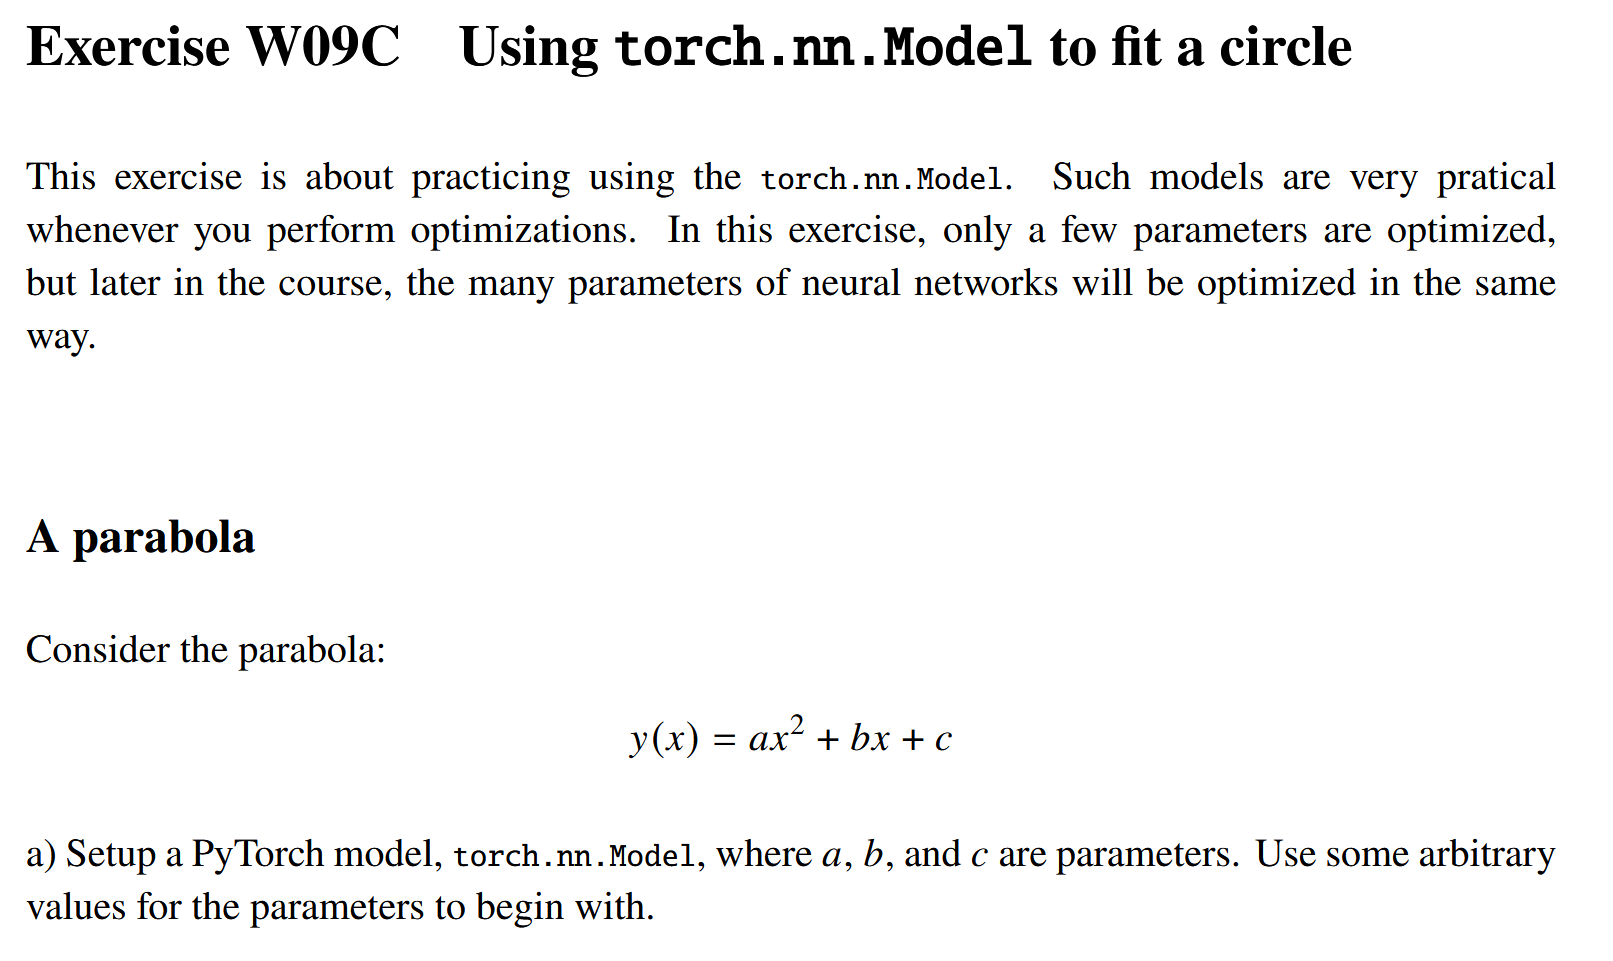
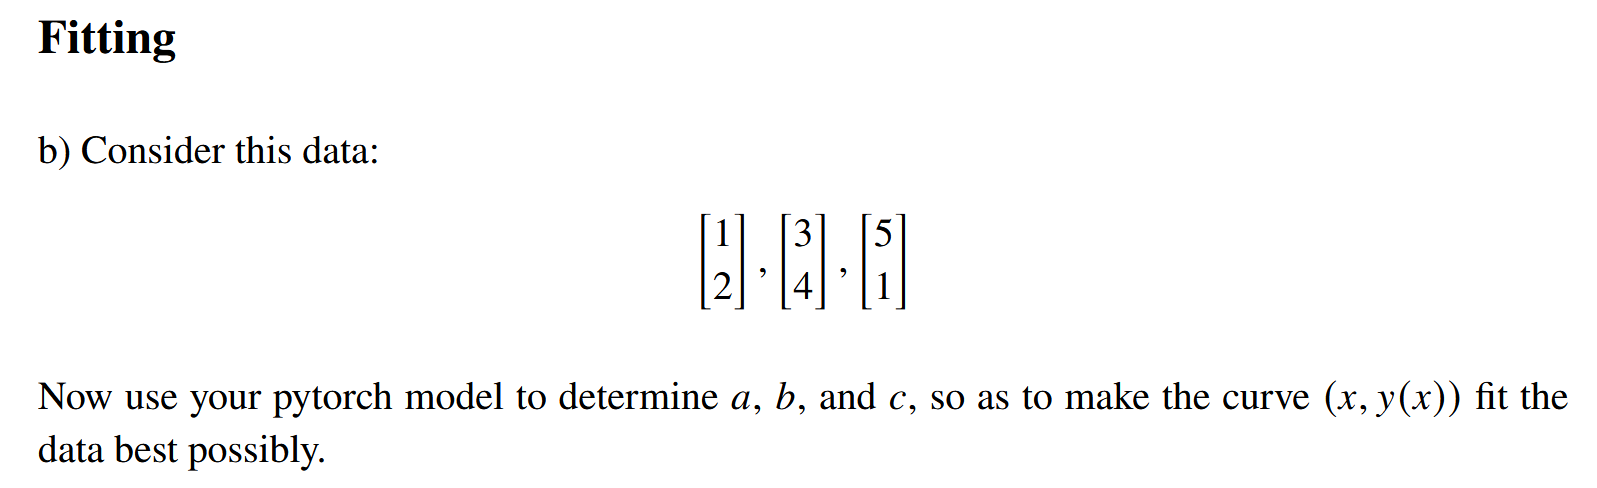
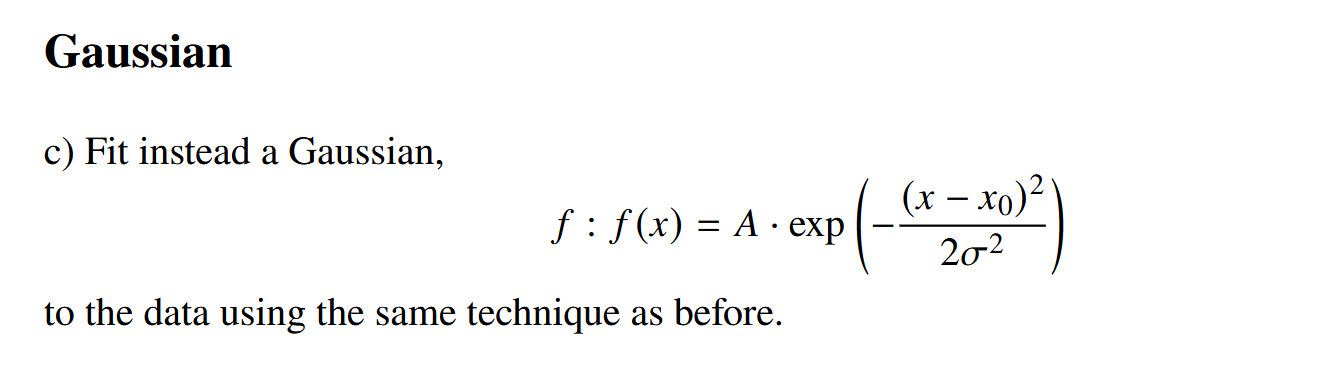
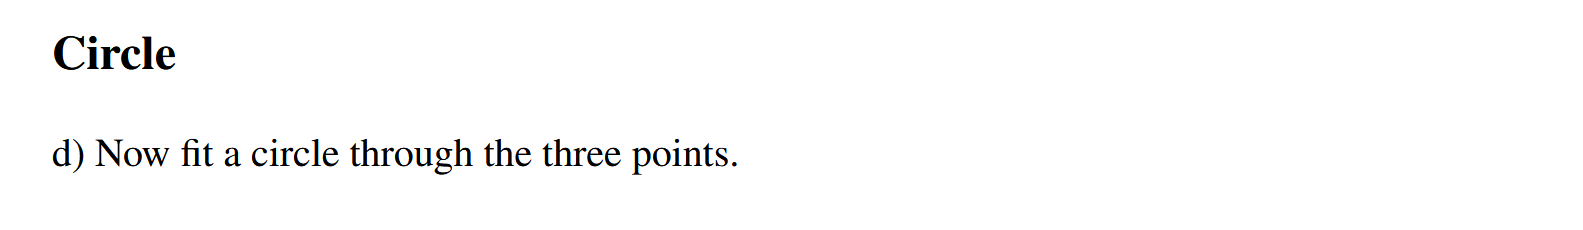

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

# Data provided in the exercise
x_data = torch.tensor([1.0, 3.0, 5.0])
y_data = torch.tensor([2.0, 4.0, 1.0])

# Helper function to plot results
def plot_fit(x_data, y_data, model_func, title, x_range=(0, 6)):
    plt.figure(figsize=(6, 4))
    plt.scatter(x_data.numpy(), y_data.numpy(), color='red', label='Data points')
    
    x_vals = torch.linspace(x_range[0], x_range[1], 100)
    with torch.no_grad():
        y_vals = model_func(x_vals)
        
    plt.plot(x_vals.numpy(), y_vals.numpy(), label='Fitted model', color='blue')
    plt.title(title)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    plt.grid(True)
    plt.show()

Parabola parameters: a=-0.625, b=3.498, c=-0.873


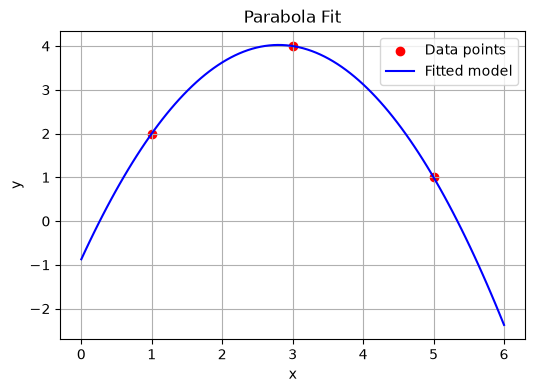

In [2]:
# a) Setup a PyTorch model for the parabola[cite: 7]
class ParabolaModel(nn.Module):
    def __init__(self):
        super().__init__()
        # Initialize parameters with arbitrary values[cite: 7]
        self.a = nn.Parameter(torch.tensor(-1.0))
        self.b = nn.Parameter(torch.tensor(1.0))
        self.c = nn.Parameter(torch.tensor(1.0))

    def forward(self, x):
        return self.a * x**2 + self.b * x + self.c

# b) Use the pytorch model to determine a, b, and c[cite: 8]
parabola_model = ParabolaModel()
optimizer = optim.Adam(parabola_model.parameters(), lr=0.1)
criterion = nn.MSELoss()

for epoch in range(2000):
    optimizer.zero_grad()
    predictions = parabola_model(x_data)
    loss = criterion(predictions, y_data)
    loss.backward()
    optimizer.step()

print(f"Parabola parameters: a={parabola_model.a.item():.3f}, b={parabola_model.b.item():.3f}, c={parabola_model.c.item():.3f}")
plot_fit(x_data, y_data, parabola_model, "Parabola Fit")

Gaussian parameters: A=4.117, x0=2.667, sigma=1.387


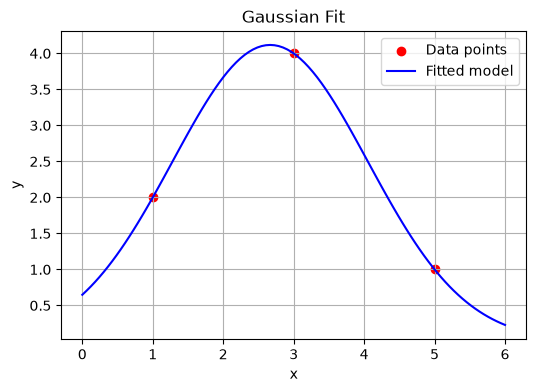

In [3]:
# c) Fit a Gaussian to the data[cite: 9]
class GaussianModel(nn.Module):
    def __init__(self):
        super().__init__()
        # Sensible initial guesses based on data (peak near x=3, y=4)
        self.A = nn.Parameter(torch.tensor(4.0))
        self.x0 = nn.Parameter(torch.tensor(3.0))
        self.sigma = nn.Parameter(torch.tensor(1.0))

    def forward(self, x):
        return self.A * torch.exp(-((x - self.x0)**2) / (2 * self.sigma**2))

gaussian_model = GaussianModel()
optimizer_g = optim.Adam(gaussian_model.parameters(), lr=0.05)

for epoch in range(2000):
    optimizer_g.zero_grad()
    predictions = gaussian_model(x_data)
    loss = criterion(predictions, y_data)
    loss.backward()
    optimizer_g.step()

print(f"Gaussian parameters: A={gaussian_model.A.item():.3f}, x0={gaussian_model.x0.item():.3f}, sigma={gaussian_model.sigma.item():.3f}")
plot_fit(x_data, y_data, gaussian_model, "Gaussian Fit")

Circle parameters: center=(3.100, 1.900), Radius=2.102


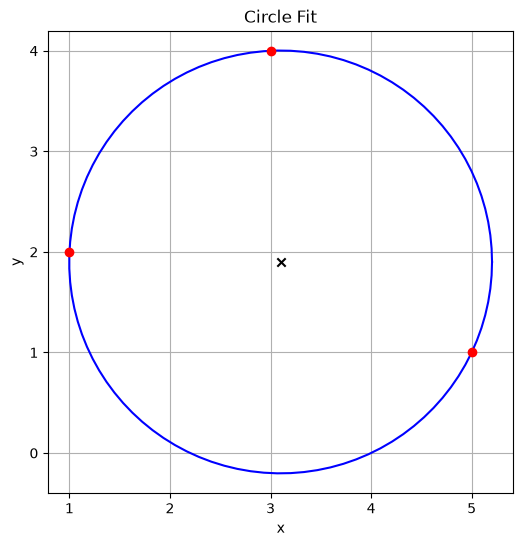

In [9]:
# d) Now fit a circle through the three points[cite: 10]
class CircleModel(nn.Module):
    def __init__(self):
        super().__init__()
        # Parameters: center (xc, yc) and radius R
        self.xc = nn.Parameter(torch.tensor(3.0))
        self.yc = nn.Parameter(torch.tensor(2.0))
        self.R = nn.Parameter(torch.tensor(2.0))

    def forward(self, x, y):
        # Calculate squared distance from points to center
        return (x - self.xc)**2 + (y - self.yc)**2

circle_model = CircleModel()
optimizer_c = optim.Adam(circle_model.parameters(), lr=0.01)

# Loss targets the squared radius
for epoch in range(3000):
    optimizer_c.zero_grad()
    # The output is the squared distances
    sq_distances = circle_model(x_data, y_data)
    # We want these distances to equal R^2
    target = (circle_model.R**2).expand_as(sq_distances)
    
    loss = criterion(sq_distances, target)
    loss.backward()
    optimizer_c.step()

xc, yc, R = circle_model.xc.item(), circle_model.yc.item(), torch.abs(circle_model.R).item()
print(f"Circle parameters: center=({xc:.3f}, {yc:.3f}), Radius={R:.3f}")

# Plotting the circle requires a parametric approach
plt.figure(figsize=(6, 6))
plt.scatter(x_data.numpy(), y_data.numpy(), color='red', label='Data points', zorder=5)

# Generate circle coordinates
theta = np.linspace(0, 2*np.pi, 100)
x_circle = xc + R * np.cos(theta)
y_circle = yc + R * np.sin(theta)

plt.plot(x_circle, y_circle, label='Fitted Circle', color='blue')
plt.scatter([xc], [yc], color='black', marker='x', label='Center')
plt.title("Circle Fit")
plt.xlabel('x')
plt.ylabel('y')
plt.axis('equal') # Ensure circle isn't distorted
plt.grid(True)
plt.show()